In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from sqlalchemy import create_engine

%matplotlib inline
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 120

PROJECT_ROOT = Path("/mnt/d/IDC409_Project15")
DB_PATH      = PROJECT_ROOT / "data" / "processed" / "house_prices.db"
FIGURES_DIR  = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

engine = create_engine(f"sqlite:///{DB_PATH}")
df = pd.read_sql("SELECT * FROM house_prices_clean", con=engine)

print(f"Loaded: {df.shape[0]:,} rows × {df.shape[1]} columns")

Loaded: 250,000 rows × 24 columns


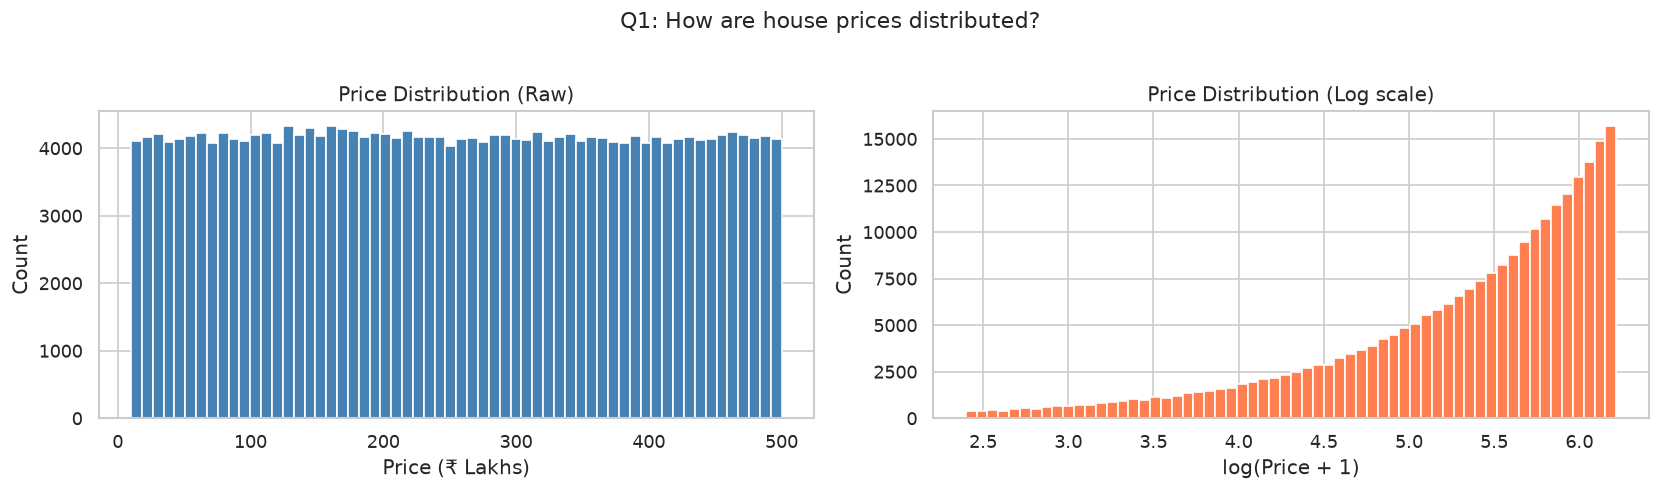

Price range  : ₹10L – ₹500L
Median price : ₹253.9L
Mean price   : ₹254.6L

Note: Near-uniform distribution confirms synthetic dataset.


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Left: raw price
axes[0].hist(df['Price_in_Lakhs'], bins=60, color='steelblue', edgecolor='white')
axes[0].set_title('Price Distribution (Raw)')
axes[0].set_xlabel('Price (₹ Lakhs)')
axes[0].set_ylabel('Count')

# Right: log-transformed price
# Log transform is standard for prices — compresses the scale so
# differences between cheap houses are visible alongside expensive ones
axes[1].hist(np.log1p(df['Price_in_Lakhs']), bins=60,
             color='coral', edgecolor='white')
axes[1].set_title('Price Distribution (Log scale)')
axes[1].set_xlabel('log(Price + 1)')
axes[1].set_ylabel('Count')

plt.suptitle('Q1: How are house prices distributed?', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_01_price_distribution.png", bbox_inches='tight')
plt.show()

print(f"Price range  : ₹{df['Price_in_Lakhs'].min():.0f}L – ₹{df['Price_in_Lakhs'].max():.0f}L")
print(f"Median price : ₹{df['Price_in_Lakhs'].median():.1f}L")
print(f"Mean price   : ₹{df['Price_in_Lakhs'].mean():.1f}L")
print(f"\nNote: Near-uniform distribution confirms synthetic dataset.")

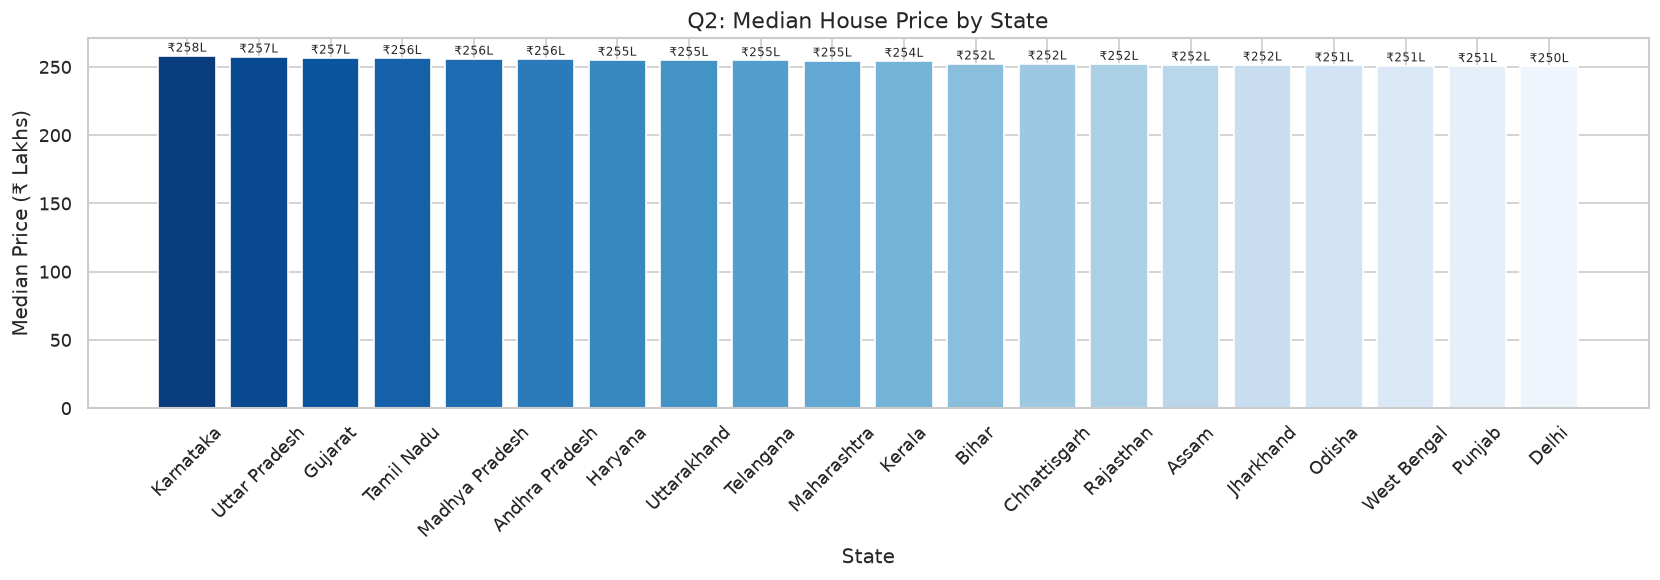

Most expensive state  : Karnataka  (₹258.1L median)
Least expensive state : Delhi  (₹250.4L median)


In [3]:
# Calculate median price per state (median is better than mean for prices —
# one very expensive property won't distort the median)
state_price = (df.groupby('State')['Price_in_Lakhs']
               .median()
               .sort_values(ascending=False))

fig, ax = plt.subplots(figsize=(14, 5))
bars = ax.bar(state_price.index, state_price.values,
              color=sns.color_palette("Blues_r", len(state_price)))
ax.set_title('Q2: Median House Price by State', fontsize=13)
ax.set_xlabel('State')
ax.set_ylabel('Median Price (₹ Lakhs)')
ax.tick_params(axis='x', rotation=45)

# Add value labels on top of each bar
for bar, val in zip(bars, state_price.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'₹{val:.0f}L', ha='center', va='bottom', fontsize=7)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_02_price_by_state.png", bbox_inches='tight')
plt.show()

print(f"Most expensive state  : {state_price.index[0]}  (₹{state_price.iloc[0]:.1f}L median)")
print(f"Least expensive state : {state_price.index[-1]}  (₹{state_price.iloc[-1]:.1f}L median)")

/tmp/ipykernel_3154/3901673692.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=city_price.index, y=city_price.values,


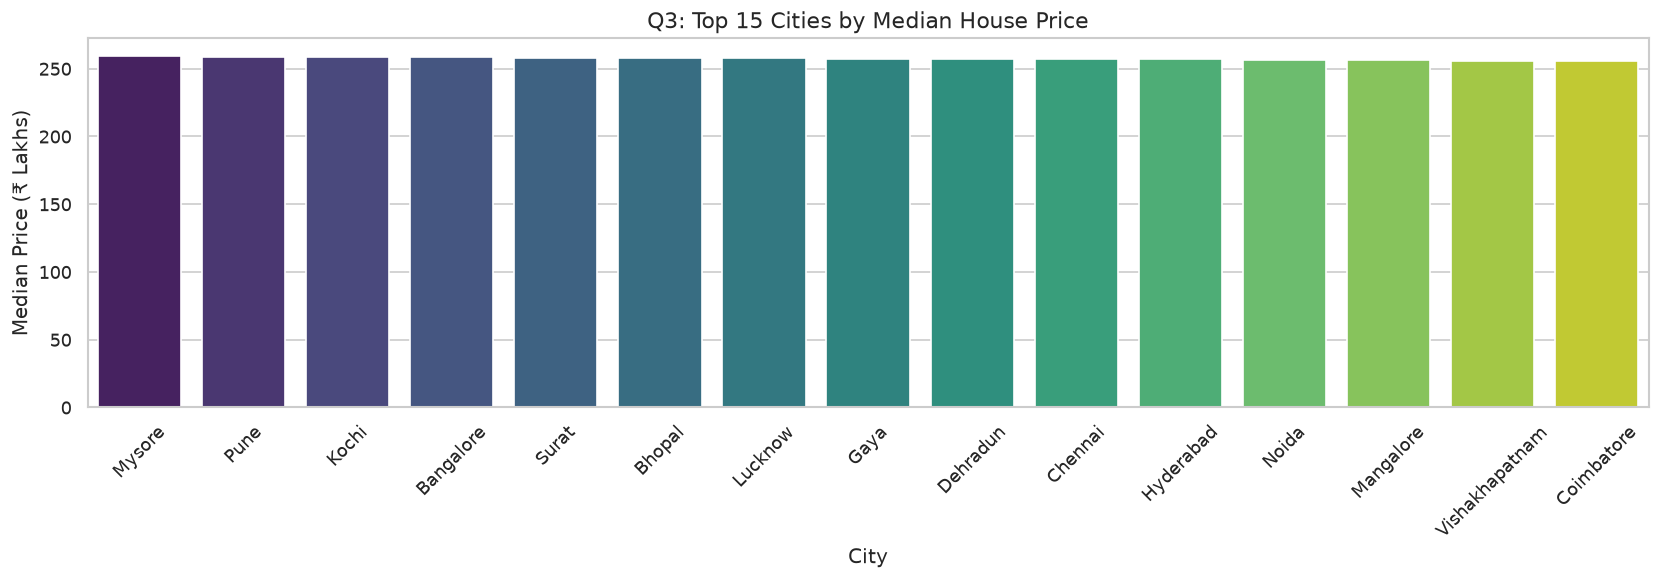

City
Mysore            259.520
Pune              258.930
Kochi             258.750
Bangalore         258.360
Surat             258.230
Bhopal            258.230
Lucknow           258.040
Gaya              257.200
Dehradun          257.035
Chennai           256.915
Hyderabad         256.780
Noida             256.520
Mangalore         256.520
Vishakhapatnam    255.740
Coimbatore        255.680


In [4]:
city_price = (df.groupby('City')['Price_in_Lakhs']
              .median()
              .sort_values(ascending=False)
              .head(15))

fig, ax = plt.subplots(figsize=(14, 5))
sns.barplot(x=city_price.index, y=city_price.values,
            palette="viridis", ax=ax)
ax.set_title('Q3: Top 15 Cities by Median House Price', fontsize=13)
ax.set_xlabel('City')
ax.set_ylabel('Median Price (₹ Lakhs)')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_03_price_by_city.png", bbox_inches='tight')
plt.show()

print(city_price.to_string())

/tmp/ipykernel_3154/2068954956.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='BHK', y='Price_in_Lakhs',


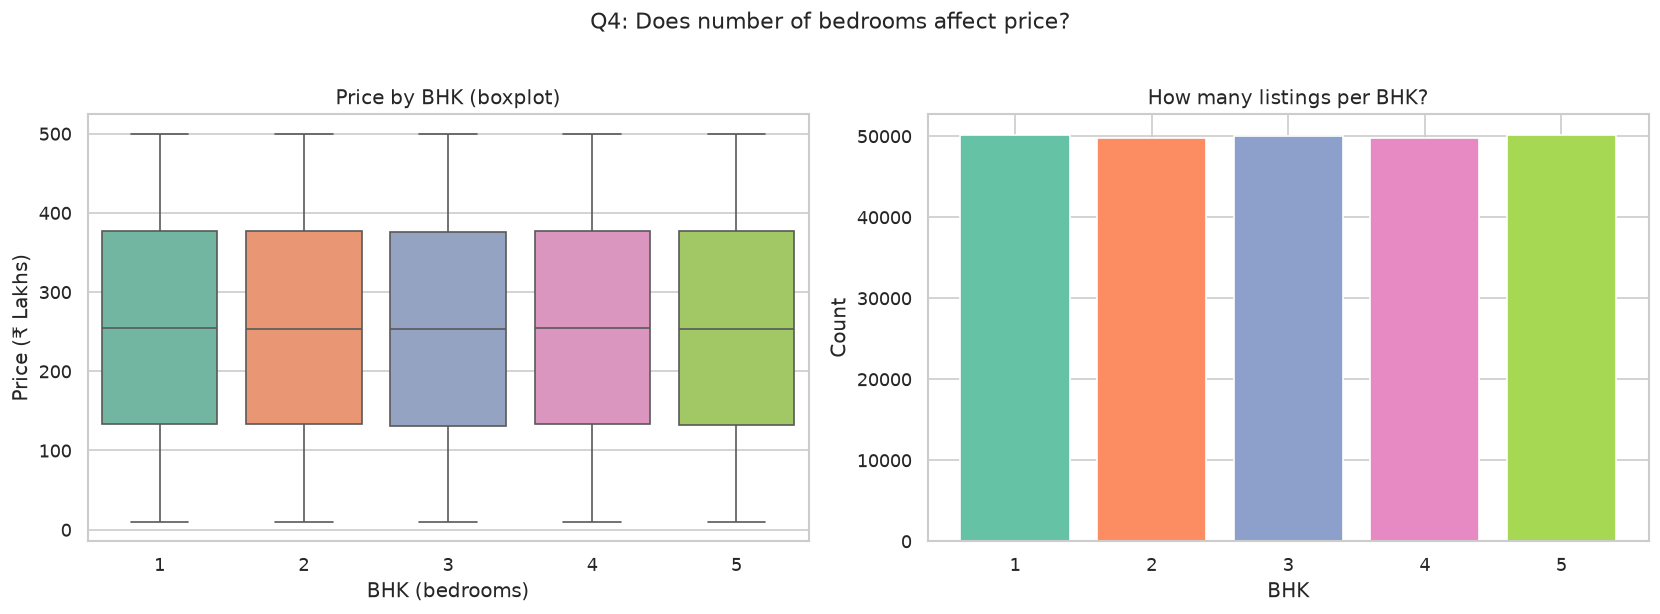

BHK
1    254.055
2    253.300
3    253.130
4    254.920
5    253.865
Name: Median Price (L), dtype: float64


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: boxplot — shows full distribution per BHK category
sns.boxplot(data=df, x='BHK', y='Price_in_Lakhs',
            palette='Set2', ax=axes[0])
axes[0].set_title('Price by BHK (boxplot)')
axes[0].set_xlabel('BHK (bedrooms)')
axes[0].set_ylabel('Price (₹ Lakhs)')

# Right: count of listings per BHK
bhk_counts = df['BHK'].value_counts().sort_index()
axes[1].bar(bhk_counts.index, bhk_counts.values,
            color=sns.color_palette("Set2"))
axes[1].set_title('How many listings per BHK?')
axes[1].set_xlabel('BHK')
axes[1].set_ylabel('Count')

plt.suptitle('Q4: Does number of bedrooms affect price?', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_04_price_by_bhk.png", bbox_inches='tight')
plt.show()

print(df.groupby('BHK')['Price_in_Lakhs'].median().rename('Median Price (L)'))

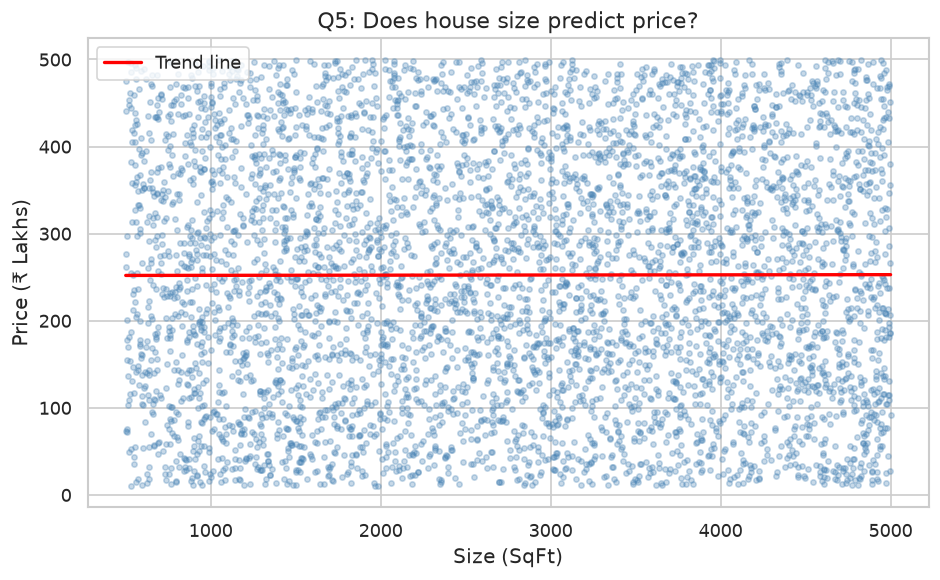

Pearson correlation (Size vs Price): -0.0025
(0 = no correlation, 1 = perfect positive, -1 = perfect negative)


In [6]:
# Sample 5000 points — plotting all 250k makes it unreadable
sample = df.sample(5000, random_state=42)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(sample['Size_in_SqFt'], sample['Price_in_Lakhs'],
           alpha=0.3, s=10, color='steelblue')
ax.set_title('Q5: Does house size predict price?', fontsize=13)
ax.set_xlabel('Size (SqFt)')
ax.set_ylabel('Price (₹ Lakhs)')

# Add a trend line
z = np.polyfit(sample['Size_in_SqFt'], sample['Price_in_Lakhs'], 1)
p = np.poly1d(z)
x_line = np.linspace(sample['Size_in_SqFt'].min(), sample['Size_in_SqFt'].max(), 100)
ax.plot(x_line, p(x_line), color='red', linewidth=2, label='Trend line')
ax.legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_05_size_vs_price.png", bbox_inches='tight')
plt.show()

corr = df['Size_in_SqFt'].corr(df['Price_in_Lakhs'])
print(f"Pearson correlation (Size vs Price): {corr:.4f}")
print("(0 = no correlation, 1 = perfect positive, -1 = perfect negative)")

/tmp/ipykernel_3154/4248975427.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=medians.index, y=medians.values, palette='pastel', ax=ax)
/tmp/ipykernel_3154/4248975427.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=medians.index, y=medians.values, palette='pastel', ax=ax)
/tmp/ipykernel_3154/4248975427.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=medians.index, y=medians.values, palette='pastel', ax=ax)


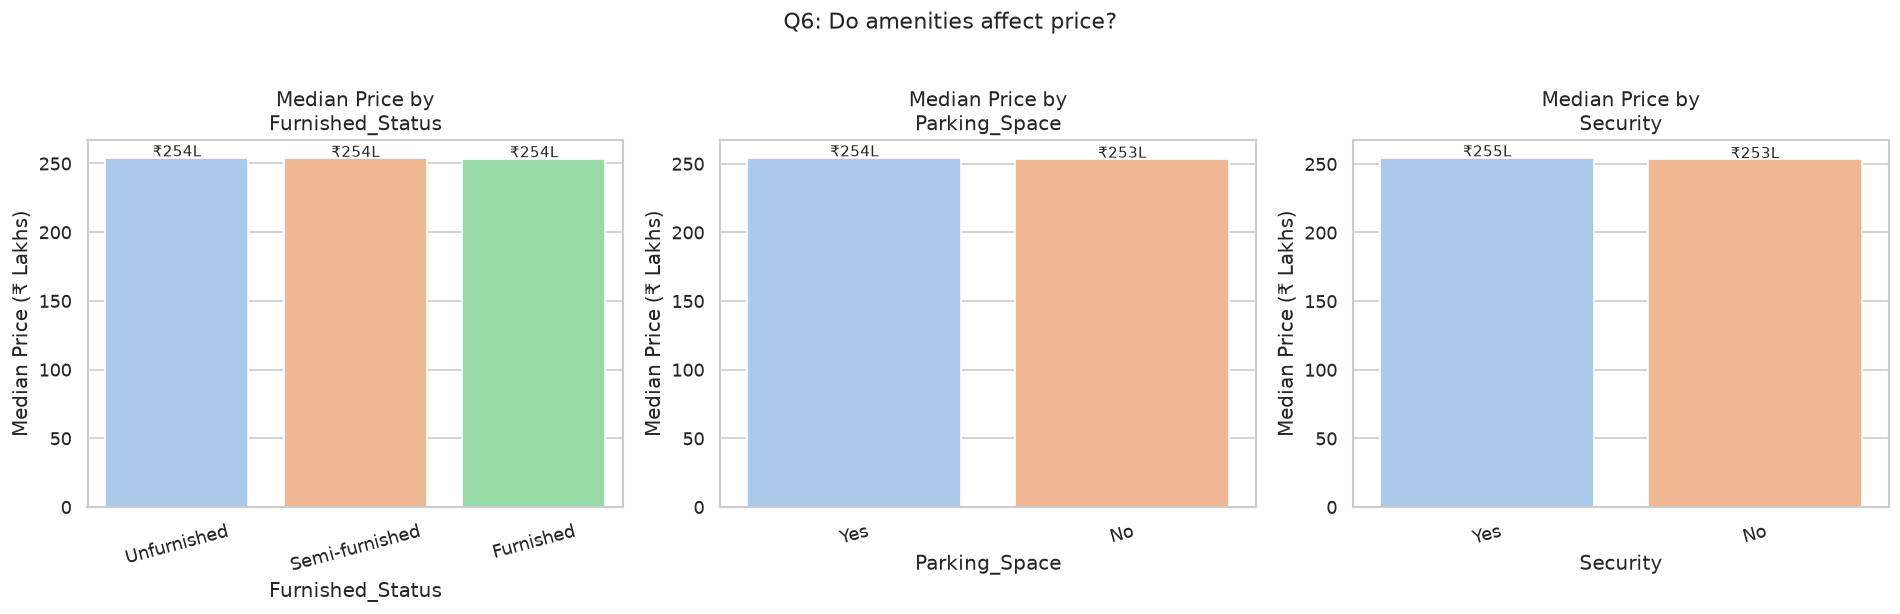

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(axes, ['Furnished_Status', 'Parking_Space', 'Security']):
    medians = df.groupby(col)['Price_in_Lakhs'].median().sort_values(ascending=False)
    sns.barplot(x=medians.index, y=medians.values, palette='pastel', ax=ax)
    ax.set_title(f'Median Price by\n{col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Median Price (₹ Lakhs)')
    ax.tick_params(axis='x', rotation=15)

    # Print exact values
    for i, (cat, val) in enumerate(medians.items()):
        ax.text(i, val + 1, f'₹{val:.0f}L', ha='center', fontsize=9)

plt.suptitle('Q6: Do amenities affect price?', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_06_amenities_vs_price.png", bbox_inches='tight')
plt.show()

/tmp/ipykernel_3154/1420764445.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=type_price.index, y=type_price.values,


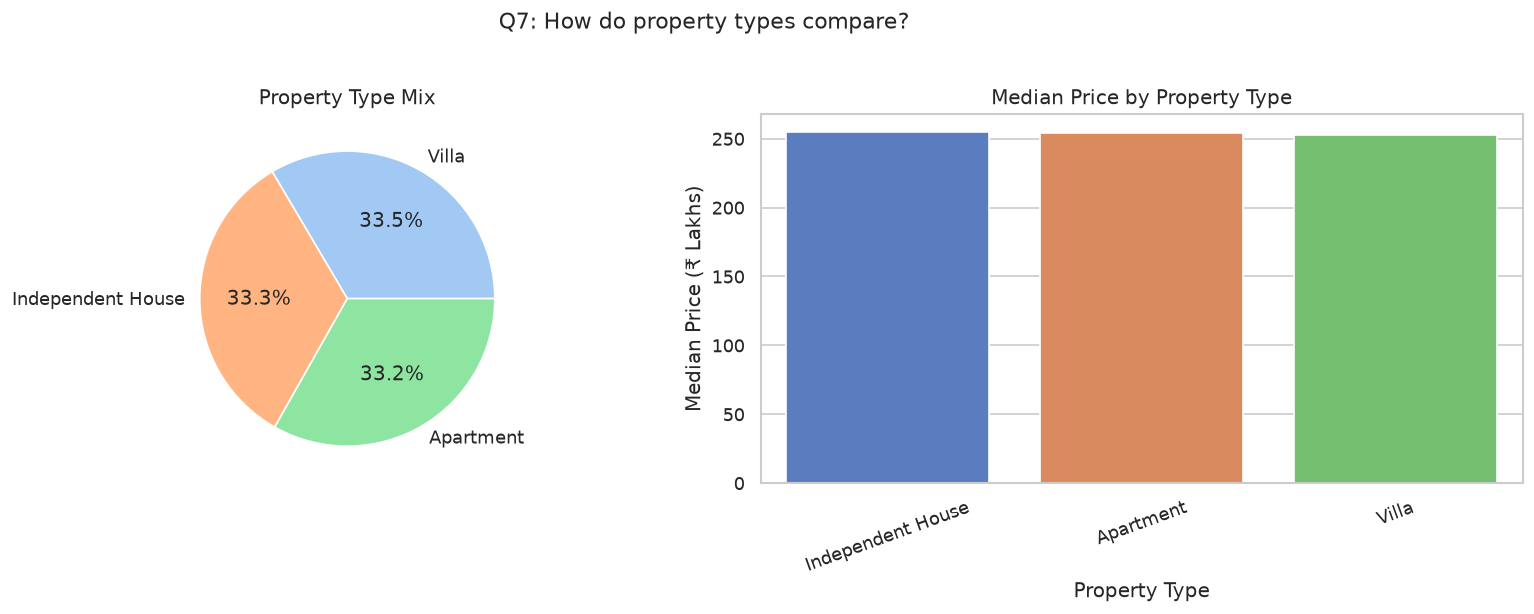

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: count of each type
type_counts = df['Property_Type'].value_counts()
axes[0].pie(type_counts.values, labels=type_counts.index,
            autopct='%1.1f%%', colors=sns.color_palette("pastel"))
axes[0].set_title('Property Type Mix')

# Right: median price per type
type_price = df.groupby('Property_Type')['Price_in_Lakhs'].median().sort_values(ascending=False)
sns.barplot(x=type_price.index, y=type_price.values,
            palette='muted', ax=axes[1])
axes[1].set_title('Median Price by Property Type')
axes[1].set_xlabel('Property Type')
axes[1].set_ylabel('Median Price (₹ Lakhs)')
axes[1].tick_params(axis='x', rotation=20)

plt.suptitle('Q7: How do property types compare?', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_07_property_type.png", bbox_inches='tight')
plt.show()

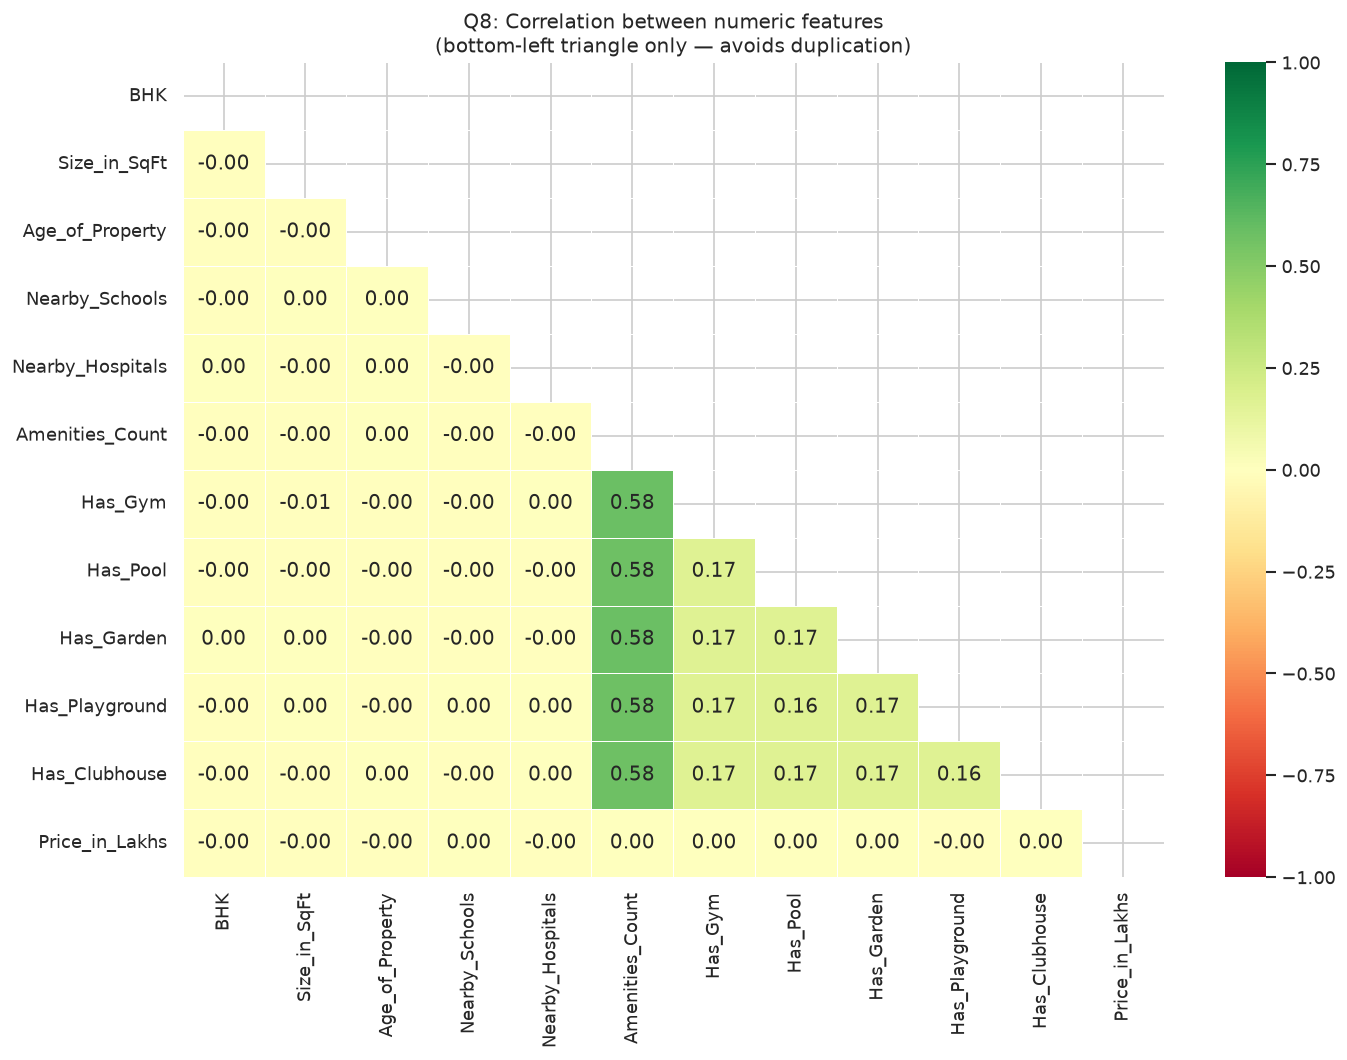

Features most correlated with Price_in_Lakhs:
Nearby_Hospitals   -0.002769
Age_of_Property    -0.002714
Size_in_SqFt       -0.002529
Has_Gym             0.001945
Has_Playground     -0.001817
Has_Pool            0.001753
Amenities_Count     0.001029
BHK                -0.000980
Has_Clubhouse       0.000607
Has_Garden          0.000482
Nearby_Schools      0.000155


In [9]:
# Select only numeric columns for correlation
# Exclude Price_per_SqFt — it's derived from the target (data leakage)
numeric_cols = [
    'BHK', 'Size_in_SqFt', 'Age_of_Property',
    'Nearby_Schools', 'Nearby_Hospitals',
    'Amenities_Count', 'Has_Gym', 'Has_Pool',
    'Has_Garden', 'Has_Playground', 'Has_Clubhouse',
    'Price_in_Lakhs'   # target — keep it last for easy reading
]

corr_matrix = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(12, 9))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))  # hide upper triangle
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f',
            cmap='RdYlGn', center=0, vmin=-1, vmax=1,
            ax=ax, linewidths=0.5)
ax.set_title('Q8: Correlation between numeric features\n(bottom-left triangle only — avoids duplication)',
             fontsize=12)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_08_correlation_heatmap.png", bbox_inches='tight')
plt.show()

# Print which features correlate most with price
price_corr = corr_matrix['Price_in_Lakhs'].drop('Price_in_Lakhs').sort_values(key=abs, ascending=False)
print("Features most correlated with Price_in_Lakhs:")
print(price_corr.to_string())

/tmp/ipykernel_3154/2943620709.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=age_price.index, y=age_price.values, palette='Blues_r', ax=ax)


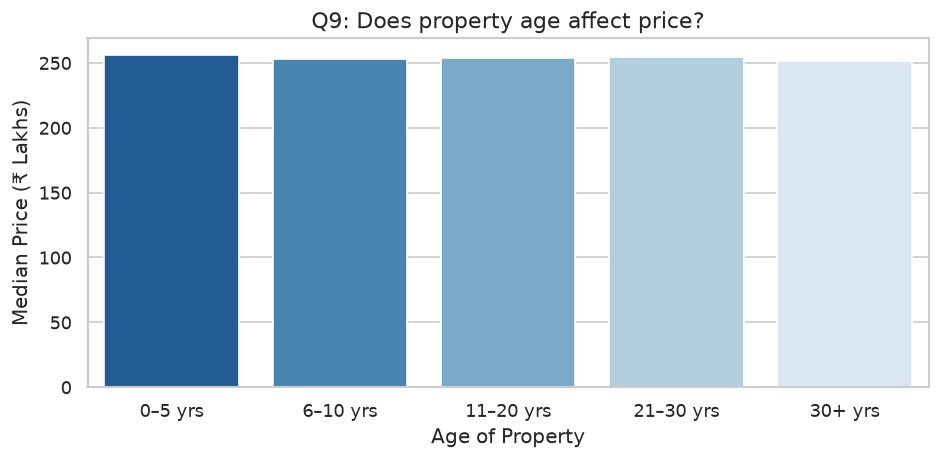

Age_Group
0–5 yrs      256.215
6–10 yrs     253.215
11–20 yrs    253.625
21–30 yrs    254.300
30+ yrs      251.735
Name: Price_in_Lakhs, dtype: float64


In [10]:
# Bin age into groups to see the trend clearly
df['Age_Group'] = pd.cut(df['Age_of_Property'],
                          bins=[0, 5, 10, 20, 30, 100],
                          labels=['0–5 yrs', '6–10 yrs', '11–20 yrs',
                                  '21–30 yrs', '30+ yrs'])

age_price = df.groupby('Age_Group', observed=True)['Price_in_Lakhs'].median()

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=age_price.index, y=age_price.values, palette='Blues_r', ax=ax)
ax.set_title('Q9: Does property age affect price?', fontsize=13)
ax.set_xlabel('Age of Property')
ax.set_ylabel('Median Price (₹ Lakhs)')
plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_09_age_vs_price.png", bbox_inches='tight')
plt.show()

print(age_price)

## EDA Summary — Key Findings

| Question | Finding |
|---|---|
| Price distribution | Near-uniform ₹10–500L — confirms synthetic data |
| Best predictor (numeric) | Check Cell 9 output — correlation with Price |
| BHK effect | Higher BHK → higher median price (expected) |
| Size effect | Weak/no correlation — again, synthetic data artefact |
| Furnishing | Furnished > Semi > Unfurnished in price |
| Property type | Villas/bungalows typically pricier than apartments |
| Age effect | Newer properties slightly more expensive |

**What this means for modelling:**  
Because the dataset is synthetic and prices are uniformly distributed,
correlations between features and price will be weak. Our models will
still be valid demonstrations of the pipeline — we just don't expect
R² values above 0.3–0.4. We will report this honestly as a dataset limitation.